## ROBOTICA

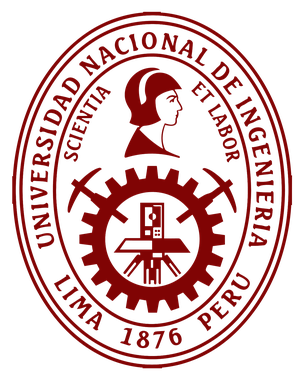

Tema: Posicion y Orientacion de un Cuerpo Rigido

---

[1] Sistema de coordenadas y transformaciones

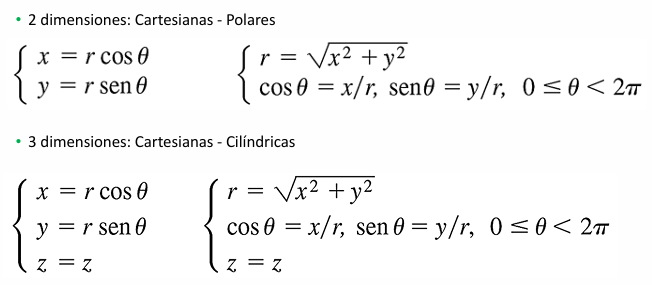
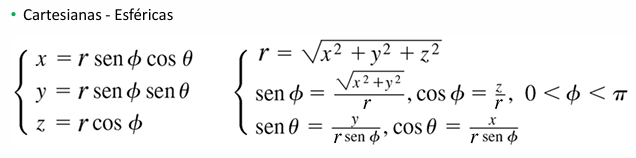

In [ ]:
import numpy as np

def Cart_Cilin(x,y,z):
    r=np.sqrt(x**2+y**2)
    teta=np.arctan2(y,x)
    if teta<0:
        teta+=2*np.pi
    return r, teta, z

def Cilin_Cart(r,teta,z):
    x=r*np.cos(teta)
    y=r*np.sin(teta)
    return x, y, z

################################

def Cart_Pola(x,y):
    r=np.sqrt(x**2+y**2)
    teta=np.arctan2(y,x)
    if teta<0:
        teta+=2*np.pi
    return r, teta

def Pola_Cart(r,teta):
    x=r*np.cos(teta)
    y=r*np.sin(teta)
    if teta<0:
        teta+=2*np.pi
    return x, y

################################
def Cart_Esfe(x,y,z):
    r=np.sqrt(x**2+y**2+z**2)
    fi=np.arctan2(np.sqrt(x**2+y**2),z)
    if fi<0:
        fi+=2*np.pi
    teta=np.arctan2(y,x)
    if teta<0:
        teta+=2*np.pi
    return r, teta, fi
def Esfe_Cart(r,teta,fi):
    x=r*np.sin(fi)*np.cos(teta)
    y=r*np.sin(fi)*np.sin(teta)
    z=r*np.cos(fi)
    return x, y, z

#ejercicio 1

#pregunta 1
print(f"(r,teta,z)={Cart_Cilin(-1,-1,3)}")
#pregunta 2
print(f"(x,y,z)={Cilin_Cart(2,2*np.pi/3,-4)}")
#pregunta 3
print(f"(x,y,z)={Esfe_Cart(4,2*np.pi/3,np.pi/6)}")
#pregunta 4
print(f"(r,teta,fi)={Cart_Esfe(-0.5,np.sqrt(3)/2,np.sqrt(3))}")


(r,teta,z)=(np.float64(1.4142135623730951), np.float64(3.9269908169872414), 3)
(x,y,z)=(np.float64(-0.9999999999999996), np.float64(1.7320508075688774), -4)
(x,y,z)=(np.float64(-0.9999999999999994), np.float64(1.7320508075688772), np.float64(3.464101615137755))
(r,teta,fi)=(np.float64(1.9999999999999998), np.float64(2.0943951023931957), np.float64(0.5235987755982988))


[2] Velocidades en diferentes sistema coordenados

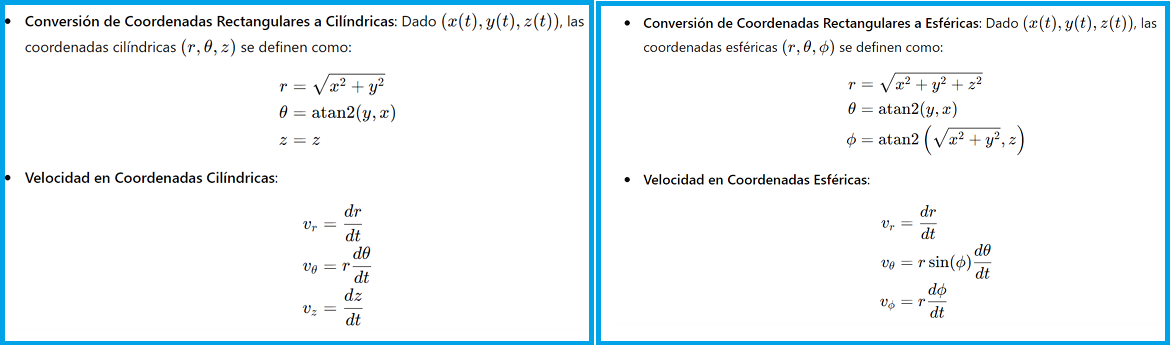

In [ ]:
#ejercicio 2
import sympy as sp
from sympy import simplify, trigsimp, sin, cos
import numpy as np
from sympy import lambdify

t = sp.symbols('t')
x=sin(t)
y=cos(t)
z=t**2

#Velocidad en coordenadas cartesianas
print(f"(dx/dt, dy/dt, dz/dt) = ({sp.diff(x,t)}, {sp.diff(y,t)}, {sp.diff(z,t)})")
vx=lambdify(t, sp.diff(x,t), 'numpy')
vy=lambdify(t, sp.diff(y,t), 'numpy')
vz=lambdify(t, sp.diff(z,t), 'numpy')
print(f"V_cartesiana=(Vx,Vy,Vz) = ({ vx(1)}, { vy(1)}, { vz(1)})")
print(f"|V_cartesiana|={np.sqrt(vx(1)**2+vy(1)**2+vz(1)**2) }")

#Velocidad en coordenadas cilíndricas
r=sp.sqrt(x**2+y**2)
teta=sp.atan2(y,x)
v_r=lambdify(t, sp.diff(r,t), 'numpy')
v_teta=lambdify(t, r*sp.diff(teta,t), 'numpy')
v_z=lambdify(t, sp.diff(z,t), 'numpy')
print(f"\nV_cilindrica=(Vr,Vteta,Vz) = ({ v_r(1)}, { v_teta(1)}, { v_z(1)})")
print(f"|V_cilindrica|={np.sqrt(v_r(1)**2+v_teta(1)**2+v_z(1)**2) }")

# Velocidad en coordenadas esféricas
r_e=sp.sqrt(x**2+y**2+z**2)
teta_e=sp.atan2(y,x)
fi_e=sp.atan2(sp.sqrt(x**2+y**2),z)
v_r_e_val=lambdify(t, sp.diff(r_e,t), 'numpy')
v_teta_e_val=lambdify(t, r_e*sp.sin(fi_e)*sp.diff(teta_e,t), 'numpy')    
v_fi_e_val=lambdify(t, r_e*sp.diff(fi_e,t), 'numpy')
print(f"\nV_esferica=(Vr,Vteta,Vfi) = ({ v_r_e_val(1)}, { v_teta_e_val(1)}, { v_fi_e_val(1)})")   
print(f"|V_esferica|={np.sqrt(v_r_e_val(1)**2+v_teta_e_val(1)**2+v_fi_e_val(1)**2) }") 

(dx/dt, dy/dt, dz/dt) = (cos(t), -sin(t), 2*t)
V_cartesiana=(Vx,Vy,Vz) = (0.5403023058681398, -0.8414709848078965, 2)
|V_cartesiana|=2.23606797749979

V_cilindrica=(Vr,Vteta,Vz) = (0, -1.0, 2)
|V_cilindrica|=2.23606797749979

V_esferica=(Vr,Vteta,Vfi) = (1.414213562373095, -1.0, -1.414213562373095)
|V_esferica|=2.2360679774997894


[3] Matriz de rotacion 2D

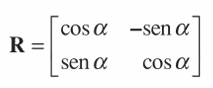

In [ ]:
t=np.pi
R=np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
x=np.array([[-3], [2]])
print(R@x)

#ejercicio 3
x=np.array([[-2], [-2]])



[[ 3.]
 [-2.]]


[4] Matriz de rotacion 3D

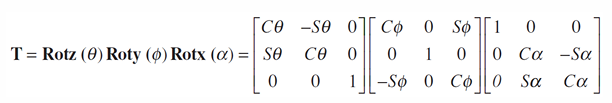

In [3]:
import numpy as np
def Rx(angle):
    return np.array([[1, 0, 0],
                     [0, np.cos(angle), -np.sin(angle)],
                     [0, np.sin(angle), np.cos(angle)]])

def Ry(angle):
    return np.array([[np.cos(angle), 0, np.sin(angle)],
                     [0, 1, 0],
                     [-np.sin(angle), 0, np.cos(angle)]])

def Rz(angle):
    return np.array([[np.cos(angle), -np.sin(angle), 0],
                     [np.sin(angle), np.cos(angle), 0],
                     [0, 0, 1]])
    
    
    
#ejercicio 4    
x=np.array([[2], [3],[4]])
angle_x=(37/180)*np.pi
angle_y=(53/180)*np.pi
angle_z=(-90/180)*np.pi

print(Rz(angle_z)@Ry(angle_y)@Rx(angle_x)@x)

[[-0.01135356]
 [-5.1967973 ]
 [ 1.41179634]]


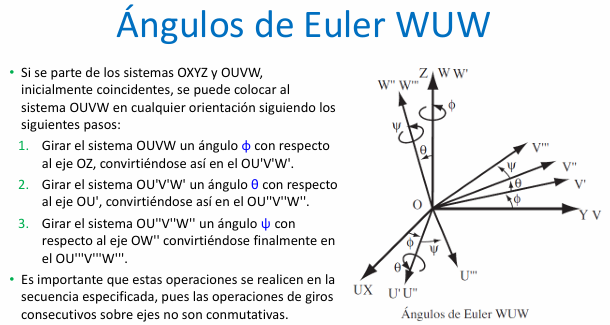

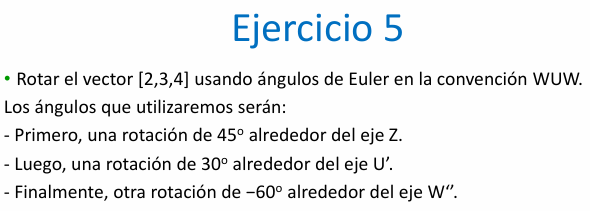

In [ ]:
#ejercicio 5
import numpy as np  
x=np.array([[2], [3],[4]])
phi=(45/180)*np.pi
teta=(30/180)*np.pi
psi=(-60/180)*np.pi

print(Rz(phi)@Rx(teta)@Rz(psi)@x)


[[4.10053917]
 [0.98790901]
 [3.34807621]]


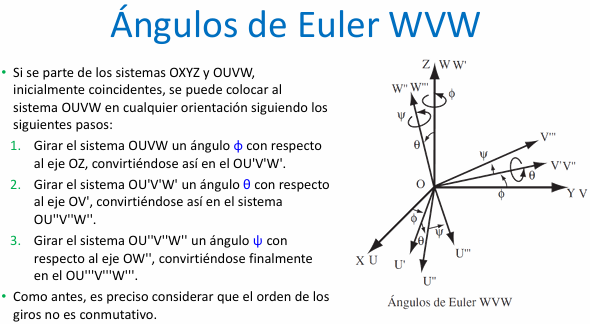

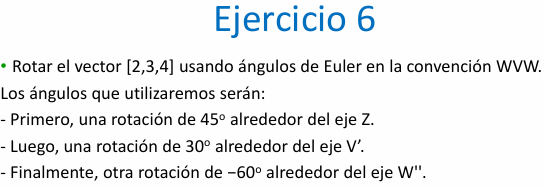

In [6]:
#ejercicio 6
import numpy as np  
x=np.array([[2], [3],[4]])
phi=(45/180)*np.pi
teta=(30/180)*np.pi
psi=(-60/180)*np.pi

print(Rz(phi)@Ry(teta)@Rz(psi)@x)

[[3.78166096]
 [3.45349156]
 [1.66506351]]


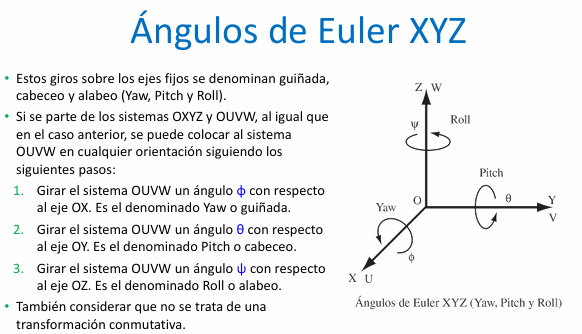

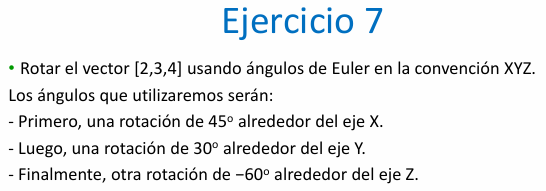

In [9]:
#ejercicio 7
import numpy as np  
x=np.array([[2], [3],[4]])
phi=(45/180)*np.pi
teta=(30/180)*np.pi
psi=(-60/180)*np.pi

print(Rz(psi)@Ry(teta)@Rx(phi)@x)

[[ 1.49108984]
 [-3.99685692]
 [ 3.28660705]]


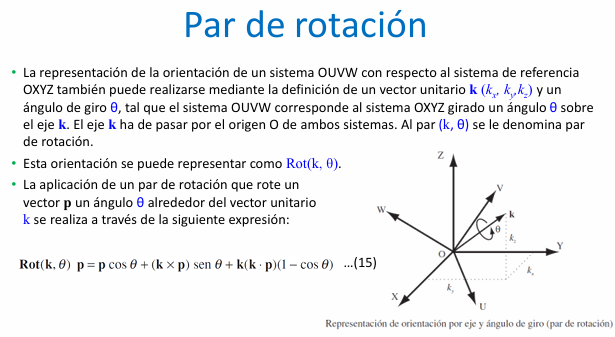

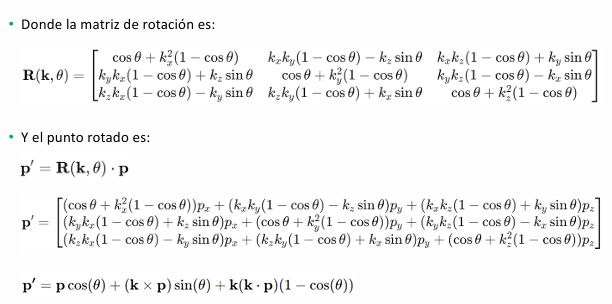

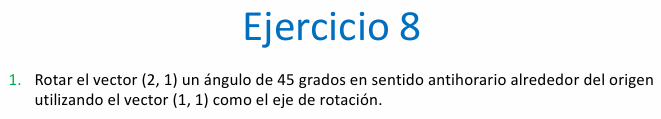

In [ ]:
import numpy as np

# p: vector [px, py, pz]
# k: eje de rotación [kx, ky, kz] sin normalizar     
# theta : ángulo en grados
def rotar_punto(p, k, theta):
    """
    Retorna:
        R      : matriz de rotación 3x3
        p_rot  : punto rotado
    """

    p = np.array(p, dtype=float)
    k = np.array(k, dtype=float)

    # Normalizar el eje de rotación
    k = k / np.linalg.norm(k)

    kx, ky, kz = k

    # Convertir grados a radianes
    theta = np.deg2rad(theta)

    c = np.cos(theta)
    s = np.sin(theta)

    R = np.array([
        [
            c + kx**2*(1-c),
            kx*ky*(1-c) - kz*s,
            kx*kz*(1-c) + ky*s
        ],
        [
            ky*kx*(1-c) + kz*s,
            c + ky**2*(1-c),
            ky*kz*(1-c) - kx*s
        ],
        [
            kz*kx*(1-c) - ky*s,
            kz*ky*(1-c) + kx*s,
            c + kz**2*(1-c)
        ]
    ])
    p_rot = R @ p
    return R, p_rot

#ejercicio 8
p=[2,1,0]
theta=45
k=[1,1,0]

R, p_rot = rotar_punto(p, k, theta)
print(f"Matriz de rotación R:\n{R}")
print(f"Punto rotado p_rot: {p_rot}")

Matriz de rotación R:
[[ 0.85355339  0.14644661  0.5       ]
 [ 0.14644661  0.85355339 -0.5       ]
 [-0.5         0.5         0.70710678]]
Punto rotado p_rot: [ 1.85355339  1.14644661 -0.5       ]
